In [1]:
import sys, os
sys.path.insert(0, os.path.abspath("/Users/morita/Library/CloudStorage/OneDrive-UTHealthHouston/srtsim/comm_try"))

In [2]:
ls /Users/morita/Library/CloudStorage/OneDrive-UTHealthHouston/srtsim/comm_try

E15/          Mouse_Embryo/ huam_lymph/


In [5]:
import h5py
import numpy as np
import pandas as pd
import scipy.sparse as sp
import anndata as ad

# --- Helper to load your specific H5 format ---
def load_custom_h5(path, feature_key='gene'):
    with h5py.File(path, 'r') as f:
        X = np.array(f['X'])
        cells = np.array(f['cell']).astype(str)
        features = np.array(f[feature_key]).astype(str)
        
        # Decode bytes if necessary
        if isinstance(cells[0], (bytes, np.bytes_)):
            cells = np.char.decode(cells, 'utf-8')
        if isinstance(features[0], (bytes, np.bytes_)):
            features = np.char.decode(features, 'utf-8')
            
        # Transpose if needed (cells should be rows)
        if X.shape[1] == len(cells):
            X = X.T
            
        return pd.DataFrame(X, index=cells, columns=features)

# --- Load Data from H5 ---
print("Loading H5 data...")
mod1_df = load_custom_h5("mouse_E15_brain/mRNA_data.h5", feature_key='gene')
mod2_df = load_custom_h5("mouse_E15_brain/ATAC_data.h5", feature_key='peak')

print(f"Loaded RNA: {mod1_df.shape}")
print(f"Loaded ATAC: {mod2_df.shape}")

# Ensure indices match
common = mod1_df.index.intersection(mod2_df.index)
mod1_df = mod1_df.loc[common]
mod2_df = mod2_df.loc[common]
print(f"Common cells: {len(common)}")

# --- Normalization (Manual Implementation to avoid Scanpy issues) ---
def normalize_modality(df, label="Modality"):
    print(f"Normalizing {label}...")
    
    # 1. Calculate total counts per cell
    total_counts = df.sum(axis=1)
    print(f"  - Mean counts before: {total_counts.mean():.2f}")
    
    # 2. Normalize to 10,000 reads per cell
    target_sum = 1e4
    # Avoid division by zero
    norm_factor = total_counts.replace(0, 1) 
    df_norm = df.div(norm_factor, axis=0) * target_sum
    
    # 3. Log transform (log(x+1))
    df_norm = np.log1p(df_norm)
    
    # Check new mean (approximate since log changes scale)
    print(f"  - Normalization complete.")
    return df_norm

mod1_df = normalize_modality(mod1_df, "RNA")
mod2_df = normalize_modality(mod2_df, "ATAC")

print("✅ Data normalized (Total count 10k + Log1p)")

Loading H5 data...
Loaded RNA: (1949, 2144)
Loaded ATAC: (1949, 47287)
Common cells: 1949
Normalizing RNA...
  - Mean counts before: 3523.66
  - Normalization complete.
Normalizing ATAC...
  - Mean counts before: 20617.36
  - Normalization complete.
✅ Data normalized (Total count 10k + Log1p)


In [69]:
import numpy as np
import pandas as pd
import scipy.sparse as sp
import anndata as ad

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import pytorch_lightning as pl

from sklearn.neighbors import kneighbors_graph
from sklearn.cluster import SpectralClustering

# -------------------------
# Config
# -------------------------
SEED        = 2027
EMBED_DIM   = 128     # latent size inside the model (inputs remain raw)
EPOCHS_COMM = 100
N_CLUSTERS  = 11
NEIGHBOR_K  = 16       # k-NN for spatial masking
GAT_HIDDEN  = 64
GAT_HEADS   = 8
GAT_DROPOUT = 0.1

COORDS_CSV    = "Mouse_E15_coords.csv"                 # index=barcode, cols: ['x','y']
TRUTH_CSV     = "barcode_truth_napari.csv"                   # index=barcode, a label column
OUTDIR        = "comm_full_out"

os.makedirs(OUTDIR, exist_ok=True)

# -------------------------
# COMPREHENSIVE SEED SETTING (CPU-OPTIMIZED FOR MAC)
# -------------------------
# Set seeds for all libraries
np.random.seed(SEED)
torch.manual_seed(SEED)

# PyTorch Lightning seed setting
pl.seed_everything(SEED, workers=True)

# Python hash seed for consistent ordering
os.environ['PYTHONHASHSEED'] = str(SEED)

# Force CPU usage (optimal for Mac)
device = torch.device("cpu")
print(f"🎯 All seeds set to {SEED} for reproducible results on CPU (Mac optimized)")

# -------------------------
# Neighborhood utilities
# -------------------------
def build_knn_mask(coords_tensor, k=8, include_self=True):
    coords_tensor = torch.as_tensor(coords_tensor, dtype=torch.float32)
    if coords_tensor.dim() != 2:
        raise ValueError("`coords_tensor` must have shape (N, D)")
    n = coords_tensor.size(0)
    if n == 0:
        raise ValueError("No coordinates provided.")
    device = coords_tensor.device
    if k <= 0:
        mask = torch.zeros(n, n, dtype=torch.bool, device=device)
        if include_self:
            mask |= torch.eye(n, dtype=torch.bool, device=device)
        return mask
    k_eff = min(k + 1, n)
    dists = torch.cdist(coords_tensor, coords_tensor)
    knn = torch.topk(dists, k=k_eff, largest=False).indices[:, 1:]
    mask = torch.zeros(n, n, dtype=torch.bool, device=device)
    row_idx = torch.arange(n, device=device).unsqueeze(1).expand_as(knn)
    mask[row_idx, knn] = True
    if include_self:
        mask |= torch.eye(n, dtype=torch.bool, device=device)
    return mask

# -------------------------
# 1) Load & align data
# -------------------------
print("📊 Loading and aligning data...")
coords_df = pd.read_csv(COORDS_CSV, index_col=0)

common = coords_df.index.intersection(mod1_df.index).intersection(mod2_df.index)
if len(common) == 0:
    raise ValueError("No shared barcodes across coords/Mod1/Mod2.")

coords = coords_df.loc[common, ['x', 'y']].to_numpy()
X_mod1  = mod1_df.loc[common].to_numpy(dtype=np.float32)   # (N, G)
X_mod2 = mod2_df.loc[common].to_numpy(dtype=np.float32)  # (N, P)
N, G = X_mod1.shape
P    = X_mod2.shape[1]
print(f"✅ Data loaded: N={N}, mod1_feats={G}, mod2_feats={P}, device={device}")

# Convert to tensors for downstream training
mod1_raw_t  = torch.from_numpy(X_mod1)
mod2_raw_t = torch.from_numpy(X_mod2)


coords_tensor = torch.from_numpy(coords).to(torch.float32)
neighbor_mask = build_knn_mask(coords_tensor, k=NEIGHBOR_K, include_self=True)

print("✅ Tensor shapes:")
print(f"   • Mod1:  {mod1_raw_t.shape}")
print(f"   • Mod2: {mod2_raw_t.shape}")
print(f"   • Coords: {coords_tensor.shape}")
print(f"   • Neighbor mask density: {neighbor_mask.float().mean().item():.4f}")

from typing import List, Union, Iterable
from copy import deepcopy

class SpatialOmicsAugmentations(torch.nn.Module):
    """
    Define spatial-omics-specific augmentations to apply to multimodal data
    (e.g., Mod1 + Mod2 matrices). Inspired by:
        [1] SimCLR (Chen et al., ICML 2020)
        [2] Factorized Contrastive Learning (Liang et al., NeurIPS 2023)
        [3] SpatialGlue / BANKSY augmentations for spatial omics

    Each input sample is a list: [X_mod1, X_mod2] (numpy arrays or tensors)
    """

    def __init__(self,
                 augmentations: Union[str, List[str]] = None,
                 p: float = 0.5,
                 random_choice: bool = False):
        super().__init__()
        if augmentations is None:
            augmentations = []
        assert isinstance(augmentations, str) or isinstance(augmentations, Iterable)
        if isinstance(augmentations, str):
            augmentations = [augmentations]

        self.augmentations = augmentations
        self.p = p
        self.random_choice = random_choice

        # mapping from string name → function
        self.registry = {
            "gaussian_noise": self.gaussian_noise,
            "feature_dropout": self.feature_dropout,
            "spot_dropout": self.spot_dropout,
            "scaled_perturb": self.scaled_perturb,
            "neighbor_mix": self.neighbor_mix,
            "simclr": self.simclr_like,
        }

    def forward(self, x: List[np.ndarray]):
        """
        x: list of modalities [X_mod1, X_mod2], shape (N, G) and (N, P)
        """
        if self.random_choice and len(self.augmentations) > 0:
            aug_name = np.random.choice(self.augmentations)
            fn = self.registry.get(aug_name, None)
            if fn is not None:
                return fn(deepcopy(x))
        else:
            for aug_name in self.augmentations:
                if np.random.rand() < self.p:
                    fn = self.registry.get(aug_name, None)
                    if fn is not None:
                        x = fn(x)
        return x

    # --------------------------------------------------
    # Augmentation functions
    # --------------------------------------------------

    @staticmethod
    def gaussian_noise(x, std=0.05):
        """Add Gaussian noise independently to each modality."""
        return [x_ + np.random.randn(*x_.shape).astype(np.float32) * std for x_ in x]

    @staticmethod
    def feature_dropout(x, frac=0.2):
        """Randomly zero out a fraction of features (columns)."""
        x_aug = []
        for x_ in x:
            drop_idx = np.random.choice(x_.shape[1],
                                        size=int(frac * x_.shape[1]),
                                        replace=False)
            x_aug_ = np.copy(x_)
            x_aug_[:, drop_idx] = 0
            x_aug.append(x_aug_)
        return x_aug

    @staticmethod
    def spot_dropout(x, frac=0.1):
        """Drop a fraction of spots (rows)."""
        x_aug = []
        drop_idx = np.random.choice(x[0].shape[0],
                                    size=int(frac * x[0].shape[0]),
                                    replace=False)
        for x_ in x:
            x_aug_ = np.copy(x_)
            x_aug_[drop_idx, :] = 0
            x_aug.append(x_aug_)
        return x_aug

    @staticmethod
    def scaled_perturb(x, scale_range=(0.9, 1.1)):
        """Randomly scale expression intensity across genes/features."""
        x_aug = []
        for x_ in x:
            scale = np.random.uniform(*scale_range, size=(1, x_.shape[1]))
            x_aug.append(x_ * scale.astype(np.float32))
        return x_aug

    @staticmethod
    def neighbor_mix(x, alpha=0.3):
        """Mix each spot with a random neighbor (spatial mixup style)."""
        n = x[0].shape[0]
        idx = np.random.permutation(n)
        lam = np.random.beta(alpha, alpha)
        return [lam * x_ + (1 - lam) * x_[idx] for x_ in x]

    @staticmethod
    def simclr_like(x):
        """SimCLR-style composite augmentation: noise + feature dropout."""
        x = SpatialOmicsAugmentations.gaussian_noise(x, std=0.05)
        x = SpatialOmicsAugmentations.feature_dropout(x, frac=0.1)
        return x

def collate_with_dual_augment(batch, augmentA=None, augmentB=None, device=None):
    """
    batch: list of ([mod1, mod2], idx) where tensors are 1D per modality.
    Returns:
      ((mod1A, mod2A), (mod1B, mod2B), batch_indices) with shapes (B, F) and (B,)
      The two views are generated via augmentations from the same base sample.
    """
    mod1 = torch.stack([item[0][0] for item in batch], dim=0)
    mod2 = torch.stack([item[0][1] for item in batch], dim=0)
    batch_indices = torch.tensor([item[1] for item in batch], dtype=torch.long)

    mod1A, mod2A = mod1.clone(), mod2.clone()
    mod1B, mod2B = mod1.clone(), mod2.clone()

    # --- Augment View A ---
    if augmentA is not None:
        mod1_np, mod2_np = mod1A.detach().cpu().numpy(), mod2A.detach().cpu().numpy()
        mod1_np, mod2_np = augmentA([mod1_np, mod2_np])
        mod1A = torch.from_numpy(mod1_np).type_as(mod1A)
        mod2A = torch.from_numpy(mod2_np).type_as(mod2A)

    # --- Augment View B ---
    if augmentB is not None:
        mod1_np, mod2_np = mod1B.detach().cpu().numpy(), mod2B.detach().cpu().numpy()
        mod1_np, mod2_np = augmentB([mod1_np, mod2_np])
        mod1B = torch.from_numpy(mod1_np).type_as(mod1B)
        mod2B = torch.from_numpy(mod2_np).type_as(mod2B)

    if device is not None:
        mod1A = mod1A.to(device); mod2A = mod2A.to(device)
        mod1B = mod1B.to(device); mod2B = mod2B.to(device)

    return (mod1A, mod2A), (mod1B, mod2B), batch_indices

# -------------------------
# 3) Dataset preparation
# -------------------------

class SpatialDataset(Dataset):
    def __init__(self, mod1_raw, mod2_raw):
        self.mod1_raw = mod1_raw
        self.mod2_raw = mod2_raw

    def __len__(self):
        return self.mod1_raw.size(0)

    def __getitem__(self, idx):
        return [self.mod1_raw[idx], self.mod2_raw[idx]], idx

class DualAugDataModule(pl.LightningDataModule):
    def __init__(self, mod1_raw, mod2_raw, coords, neighbor_mask,
                 batch_size=1024, augmentA=None, augmentB=None, device=None,
                 spot_tokenization=False):
        super().__init__()
        self.ds = SpatialDataset(mod1_raw, mod2_raw)
        self.bs = batch_size
        self.augmentA = augmentA
        self.augmentB = augmentB
        self.device = device
        self.spot_tokenization = spot_tokenization
        if coords is None:
            raise ValueError("coords tensor is required for neighborhood masking.")
        self.coords = coords
        self.neighbor_mask = neighbor_mask

        self.generator = torch.Generator()
        self.generator.manual_seed(SEED)

        def _collate(batch):
            viewA, viewB, batch_indices = collate_with_dual_augment(
                batch, augmentA=self.augmentA, augmentB=self.augmentB, device=self.device
            )
            coords_batch = self.coords[batch_indices]
            mask = None
            if self.neighbor_mask is not None:
                mask = self.neighbor_mask[batch_indices][:, batch_indices]
            meta = {
                "coords": coords_batch,
                "mask": mask,
                "indices": batch_indices
            }
            if self.spot_tokenization:
                n_modalities = len(viewA) if isinstance(viewA, (list, tuple)) else 1
                meta["token_multiplier"] = n_modalities
                meta["attn_mask_tokens"] = batch_indices.numel() * n_modalities
                if mask is not None:
                    # print(meta["attn_mask_tokens"], mask.shape, mask.sum().item())
                    pass
            return viewA, viewB, meta
        self._collate = _collate

    def train_dataloader(self):
        return DataLoader(
            self.ds, batch_size=self.bs, shuffle=True,
            num_workers=0, generator=self.generator, collate_fn=self._collate
        )


aug = SpatialOmicsAugmentations(
    augmentations=["gaussian_noise", "feature_dropout", "neighbor_mix"],
    p=0.8, random_choice=False
)

# Or different strengths per view
augA = SpatialOmicsAugmentations(augmentations=["feature_dropout"], p=0.9)
augB = SpatialOmicsAugmentations(augmentations=["feature_dropout"], p=0.9)

#augA = None
#augB = None
# ------------- build datamodule -------------
data_mod = DualAugDataModule(
    mod1_raw=mod1_raw_t, mod2_raw=mod2_raw_t,
    coords=coords_tensor, neighbor_mask=neighbor_mask,
    batch_size=2048,
    augmentA=aug,
    augmentB=aug,
    device=device,
    spot_tokenization=True
)

# -------------------------
# 4) Model setup with modular imports
# -------------------------
print("🧠 Setting up model with modular imports...")

import importlib
import CoMM.models.mmfusion as mmfusion_module
import CoMM.pl_modules.comm as comm_module
importlib.reload(mmfusion_module)
importlib.reload(comm_module)

# Use modular import structure
from CoMM.models.mmfusion import MMFusion
from CoMM.pl_modules.comm import CoMM

print("✅ Successfully imported from modular structure:")
print(f"   • MMFusion from models.mmfusion")
print(f"   • CoMM from pl_modules.comm")

class SpotTokenAdapter(nn.Module):
    collapse_batch = True
    def forward(self, x):
        return x.unsqueeze(0)

# Encoders map raw → latent (EMBED_DIM). Inputs remain raw-sized.
encoder_mod1  = nn.Sequential(nn.Linear(G, EMBED_DIM), nn.ReLU(), nn.Linear(EMBED_DIM, EMBED_DIM))
encoder_mod2 = nn.Sequential(nn.Linear(P, EMBED_DIM), nn.ReLU(), nn.Linear(EMBED_DIM, EMBED_DIM))

print(f"✅ Encoder dimensions:")
print(f"   • Mod1 encoder: {G} → {EMBED_DIM}")
print(f"   • Mod2 encoder: {P} → {EMBED_DIM}")

fusion_encoder = MMFusion(
    encoders=[encoder_mod1, encoder_mod2],
    input_adapters=[SpotTokenAdapter(), SpotTokenAdapter()],
    embed_dim=EMBED_DIM,
    fusion="concat",
    pool="tokens",
    n_heads=8,
    n_layers=1,
)

projection = CoMM._build_mlp(in_dim=EMBED_DIM, mlp_dim=256, out_dim=EMBED_DIM)

neighborhood_cfg = {
    "hidden_dim": GAT_HIDDEN,
    "heads": GAT_HEADS,
    "dropout": GAT_DROPOUT,
    "k_neighbors": NEIGHBOR_K,
    "include_self": True
}

model = CoMM(
    encoder=fusion_encoder,
    projection=projection,
    optim_kwargs={"lr":1e-3, "weight_decay":1e-5},
    loss_kwargs={"temperature":0.1},
    neighborhood_cfg=neighborhood_cfg
)

trainer = pl.Trainer(
    max_epochs=EPOCHS_COMM,
    accelerator="cpu",          # Force CPU for Mac
    devices=1,
    logger=False,
    enable_checkpointing=False,
    enable_progress_bar=True,   # Show progress
    deterministic=True          # Enable deterministic training
)
trainer.fit(model, datamodule=data_mod)

print("✅ Training completed successfully!")


Seed set to 2027
/opt/anaconda3/envs/comm/lib/python3.8/site-packages/torch/nn/modules/lazy.py:181: UserWarning: Lazy modules are a new feature under heavy development so changes to the API or functionality can happen at any moment.
  warnings.warn('Lazy modules are a new feature under heavy development '
GPU available: True (mps), used: False
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
/opt/anaconda3/envs/comm/lib/python3.8/site-packages/pytorch_lightning/trainer/setup.py:177: GPU available but not used. You can set it by doing `Trainer(accelerator='gpu')`.
/opt/anaconda3/envs/comm/lib/python3.8/site-packages/pytorch_lightning/trainer/configuration_validator.py:70: You defined a `validation_step` but have no `val_dataloader`. Skipping val loop.

  | Name              | Type            | Params | Mode 
--------------------------------------------------------------
0 | encoder           | MMFusion        | 6.6 M  | train
1 | head              | Sequentia

🎯 All seeds set to 2027 for reproducible results on CPU (Mac optimized)
📊 Loading and aligning data...
✅ Data loaded: N=1949, mod1_feats=2144, mod2_feats=47287, device=cpu
✅ Tensor shapes:
   • Mod1:  torch.Size([1949, 2144])
   • Mod2: torch.Size([1949, 47287])
   • Coords: torch.Size([1949, 2])
   • Neighbor mask density: 0.0087
🧠 Setting up model with modular imports...
DEBUG: Loading CoMM/models/mmfusion.py
✅ Successfully imported from modular structure:
   • MMFusion from models.mmfusion
   • CoMM from pl_modules.comm
✅ Encoder dimensions:
   • Mod1 encoder: 2144 → 128
   • Mod2 encoder: 47287 → 128
Epoch 99: 100%|██████████| 1/1 [00:07<00:00,  0.14it/s, loss=8.240, ssl_acc=0.231, ssl_acc_0=0.205, ssl_acc_1=0.231, ssl_acc_2=0.257, ssl_loss_0=8.250, ssl_loss_1=8.230, ssl_loss_2=8.230]    

`Trainer.fit` stopped: `max_epochs=100` reached.


Epoch 99: 100%|██████████| 1/1 [00:07<00:00,  0.14it/s, loss=8.240, ssl_acc=0.231, ssl_acc_0=0.205, ssl_acc_1=0.231, ssl_acc_2=0.257, ssl_loss_0=8.250, ssl_loss_1=8.230, ssl_loss_2=8.230]
✅ Training completed successfully!


In [70]:
# -------------------------
# 5) Extract embeddings for clustering
# -------------------------
model.eval()
with torch.no_grad():
    view_data = [mod1_raw_t, mod2_raw_t]
    n_spots = view_data[0].shape[0]
    n_modalities = len(view_data)
    full_meta = {
        "coords": coords_tensor,
        "mask": neighbor_mask,
        "token_multiplier": n_modalities,
        "attn_mask_tokens": n_spots * n_modalities
    }
    attn_mask = model._compute_attention_mask(view_data, full_meta)
    joint_emb = model.encoder(view_data, attn_mask=attn_mask).cpu().numpy()

print(f"[info] Extracted embeddings shape: {joint_emb.shape}")

[info] Extracted embeddings shape: (1949, 128)


     method  n_clusters       ARI
2  Walktrap          11  0.390836
3   Louvain          11  0.387731
4    Leiden          11  0.368054
0  Spectral          11  0.366435
1       GMM          11  0.249601


/var/folders/yh/dw7_nrr174l4yn8tpbxgzsbm0000gn/T/ipykernel_51309/1528824486.py:133: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = mpl.cm.get_cmap(cmap, n_classes)
/var/folders/yh/dw7_nrr174l4yn8tpbxgzsbm0000gn/T/ipykernel_51309/1528824486.py:133: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = mpl.cm.get_cmap(cmap, n_classes)
/var/folders/yh/dw7_nrr174l4yn8tpbxgzsbm0000gn/T/ipykernel_51309/1528824486.py:133: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = mpl.

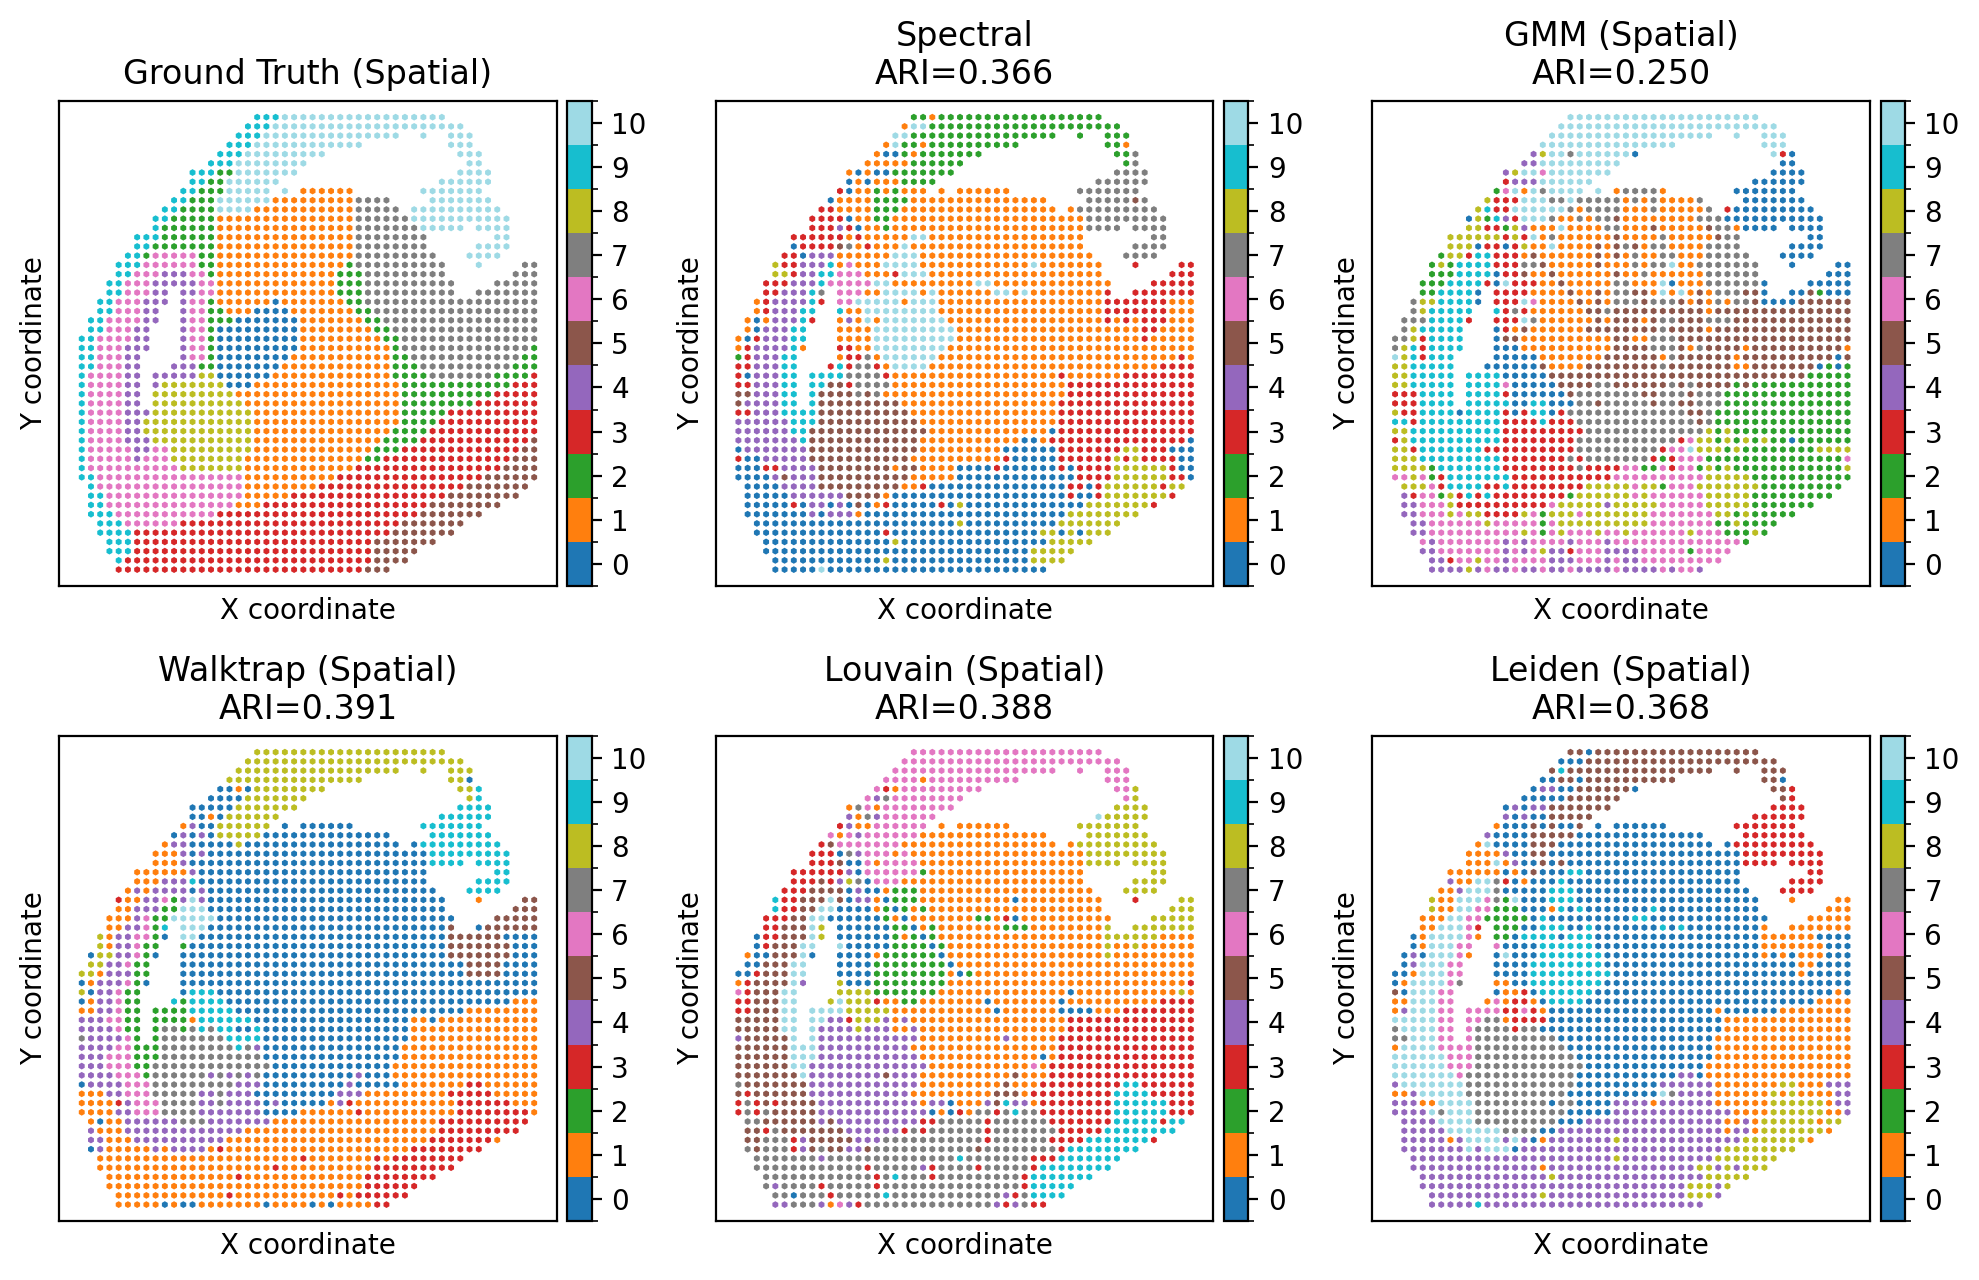

Saved: comm_full_out/spatial_panel_k11_2000x1300.png
🎯 Results should now be reproducible with seed=2027


In [ ]:
# ==== panel like screenshot: 2x3 hex "spatial" plots with per-axis colorbars ====
import numpy as np, os, pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
from sklearn.metrics import adjusted_rand_score
from sklearn.cluster import SpectralClustering
from sklearn.mixture import GaussianMixture
from sklearn.neighbors import kneighbors_graph
from sklearn.preprocessing import LabelEncoder
import igraph as ig
import networkx as nx
import community as community_louvain
# --- add after your imports ---
try:
    import leidenalg as la
    _HAS_LEIDEN = True
except Exception:
    _HAS_LEIDEN = False
    print("⚠️ 'leidenalg' not found; lower-right panel will fall back to Ground Truth.")


def leiden_clustering(X, n_clusters, n_neighbors=10, seed=2025, resolution=1.0):
    """
    Build a kNN graph on X, run Leiden, then coerce to exactly n_clusters:
    - if too many, merge smallest communities into the largest until k
    - if too few, fallback to spectral to split to k
    """
    # kNN connectivity graph (undirected)
    A = kneighbors_graph(X, n_neighbors=n_neighbors, include_self=False, mode="connectivity")
    A = 0.5 * (A + A.T)
    s, t = A.nonzero()
    w = A[s, t].A1
    g = ig.Graph(edges=list(zip(s.tolist(), t.tolist())), directed=False)
    if w.size > 0:
        g.es["weight"] = w.tolist()

    # Leiden with resolution control
    part = la.find_partition(
        g,
        la.RBConfigurationVertexPartition,
        weights="weight",
        resolution_parameter=resolution,
        seed=seed,
    )
    labels = np.array(part.membership, dtype=int)

    # Coerce to exactly n_clusters (same policy you used for Louvain)
    uniq = np.unique(labels)
    if len(uniq) > n_clusters:
        counts = sorted(((lab, (labels == lab).sum()) for lab in uniq), key=lambda x: x[1])
        target = counts[-1][0]  # merge into largest
        for lab, _ in counts[: len(uniq) - n_clusters]:
            labels[labels == lab] = target
    elif len(uniq) < n_clusters:
        spec = SpectralClustering(n_clusters=n_clusters, affinity="precomputed", random_state=seed)
        labels = spec.fit_predict(A.toarray())
    return labels



# --- ground truth + coords (aligned to `common`) ---
truth_df = pd.read_csv(TRUTH_CSV, index_col=0)
truth    = truth_df.loc[common, 'region_truth']
le = LabelEncoder()
truth_codes = le.fit_transform(truth)
coords_xy = coords_df.loc[common, ['x','y']].values

# --- helpers: walktrap / louvain (fixed cluster count) ---
def walktrap_clustering(X, n_clusters, n_neighbors=10):
    A = kneighbors_graph(X, n_neighbors=n_neighbors, include_self=False)
    A = 0.5*(A + A.T)
    s, t = A.nonzero(); w = A[s, t].A1
    g = ig.Graph(edges=list(zip(s.tolist(), t.tolist())), directed=False)
    g.es['weight'] = w
    return np.array(g.community_walktrap(weights='weight').as_clustering(n=n_clusters).membership)

def louvain_clustering(X, n_clusters, n_neighbors=10, seed=2025):
    A = kneighbors_graph(X, n_neighbors=n_neighbors, include_self=False)
    A = 0.5*(A + A.T)
    G = nx.Graph()
    s, t = A.nonzero(); w = A[s, t].A1
    for u,v,ww in zip(s, t, w): G.add_edge(int(u), int(v), weight=float(ww))
    part = community_louvain.best_partition(G, random_state=seed, weight='weight')
    labels = np.array([part[i] for i in range(G.number_of_nodes())])
    uniq = np.unique(labels)
    if len(uniq) > n_clusters:
        cnts = [(lab, (labels==lab).sum()) for lab in uniq]
        cnts.sort(key=lambda x: x[1])
        target = cnts[-1][0]
        for lab,_ in cnts[:len(uniq)-n_clusters]:
            labels[labels==lab] = target
    elif len(uniq) < n_clusters:
        spec = SpectralClustering(n_clusters=n_clusters, affinity='precomputed', random_state=seed)
        labels = spec.fit_predict(A.toarray())
    return labels

# --- embeddings (already extracted from training) ---
# joint_emb is now available from the previous cell

k = N_CLUSTERS

# -------------------------
# FIXED CLUSTERING WITH CONSISTENT SEEDS
# -------------------------
clusterings = {
    'Spectral': SpectralClustering(n_clusters=k, affinity='nearest_neighbors',
                                   random_state=SEED).fit_predict(joint_emb),
    'GMM':      GaussianMixture(n_components=k, random_state=SEED).fit_predict(joint_emb),
    'Walktrap': walktrap_clustering(joint_emb, k),
    'Louvain':  louvain_clustering(joint_emb, k, seed=SEED),
}

# NEW: add Leiden if available with proper seed
if _HAS_LEIDEN:
    clusterings['Leiden'] = leiden_clustering(joint_emb, k, n_neighbors=10, seed=SEED, resolution=1.0)

# --- ARIs table unchanged ---
df_ari = pd.DataFrame(
    [{'method': m, 'n_clusters': k, 'ARI': adjusted_rand_score(truth_codes, y)}
     for m, y in clusterings.items()]
).sort_values('ARI', ascending=False)
os.makedirs(OUTDIR, exist_ok=True)
df_ari.to_csv(os.path.join(OUTDIR, f"cluster_ARI_k{k}.csv"), index=False)
print(df_ari)

# --- plotting (replace the lower-right panel with Leiden if present) ---
TARGET_PX = (2000, 1300)
DPI = 200
fig = plt.figure(figsize=(TARGET_PX[0]/DPI, TARGET_PX[1]/DPI), dpi=DPI)
axes = [fig.add_subplot(2,3,i) for i in range(1,7)]

def make_discrete_cb(ax, n_classes, cmap='tab20'):
    cmap = mpl.cm.get_cmap(cmap, n_classes)
    bounds = np.arange(-0.5, n_classes+0.5, 1)
    norm = mpl.colors.BoundaryNorm(bounds, cmap.N)
    sm = mpl.cm.ScalarMappable(cmap=cmap, norm=norm)
    cbar = plt.colorbar(sm, ax=ax, fraction=0.046, pad=0.02, ticks=np.arange(n_classes))
    return cmap, norm, cbar


def scatter_hex(ax, xy, labels, title, n_classes, cmap='tab20'):
    cmap, norm, _ = make_discrete_cb(ax, n_classes, cmap)
    ax.scatter(xy[:,0], xy[:,1], c=labels, cmap=cmap, norm=norm,
               s=6, marker='h', linewidths=0)
    ax.set_title(title, fontsize=12)
    ax.set_xlabel("X coordinate"); ax.set_ylabel("Y coordinate")
    ax.axis('equal'); ax.set_xticks([]); ax.set_yticks([])

# row 1: GT, Spectral, GMM
scatter_hex(axes[0], coords_xy, truth_codes, "Ground Truth (Spatial)", n_classes=len(np.unique(truth_codes)))
for ax, (name, pred) in zip(axes[1:3], [('Spectral', clusterings['Spectral']),
                                        ('GMM (Spatial)', clusterings['GMM'])]):
    ari = adjusted_rand_score(truth_codes, pred)
    scatter_hex(ax, coords_xy, pred, f"{name}\nARI={ari:.3f}", n_classes=k)

# row 2: Walktrap, Louvain, Leiden (or fallback GT)
ari_w = adjusted_rand_score(truth_codes, clusterings['Walktrap'])
scatter_hex(axes[3], coords_xy, clusterings['Walktrap'], f"Walktrap (Spatial)\nARI={ari_w:.3f}", n_classes=k)

ari_l = adjusted_rand_score(truth_codes, clusterings['Louvain'])
scatter_hex(axes[4], coords_xy, clusterings['Louvain'], f"Louvain (Spatial)\nARI={ari_l:.3f}", n_classes=k)

if 'Leiden' in clusterings:
    ari_le = adjusted_rand_score(truth_codes, clusterings['Leiden'])
    scatter_hex(axes[5], coords_xy, clusterings['Leiden'], f"Leiden (Spatial)\nARI={ari_le:.3f}", n_classes=k)
else:
    scatter_hex(axes[5], coords_xy, truth_codes, "Ground Truth (Spatial)", n_classes=len(np.unique(truth_codes)))



fig.tight_layout()
out_png = os.path.join(OUTDIR, f"spatial_panel_k{k}_{TARGET_PX[0]}x{TARGET_PX[1]}.png")
fig.savefig(out_png, dpi=DPI, bbox_inches='tight')
plt.show()
print(f"Saved: {out_png}")
print(f"🎯 Results should now be reproducible with seed={SEED}")
